Discente: **Brener Gomes dos Santos**

Data: **06/02**

# Setup

In [13]:
import gdown
import cv2

import numpy as np
import matplotlib.pyplot as plt

from skimage import data, color, img_as_float
from skimage.util import img_as_ubyte
from skimage import data
from skimage.morphology import disk
from skimage.filters import median

from skimage.filters import prewitt_h, prewitt_v, sobel_h, sobel_v, roberts

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from skimage.filters import threshold_otsu

from skimage.morphology import (
    footprint_rectangle,
    diamond,
    disk,
    octahedron,
    ball,
    octagon,
    star,
)

from skimage.morphology import binary_erosion
from skimage.morphology import binary_dilation
from skimage.morphology import binary_closing
from skimage.morphology import binary_opening

from scipy import ndimage as ndi


# Seleção da imagem do **Dataset**

* Gabarito das imagens que compõe o dataset



```
ID                                  Nome
1u06UwmbtFm-RVc0EFIIoBvMkwIMFQS6q - controle_1.jpg
1DTI0AM46spTxb6jbagFPWMah9WKhy_Mm - controle_2.jpg
1fpEkhlXFxxmazoDTNkk83hu7-KjTHeZ7 - controle_3.jpg
1IulBEA6tH5OhKo3VjPdk74UbREGEqRcA - headset_1.jpg
1eyXD2n0u2HUOY2nwk9lkLyIqC6jthlh7 - headset_2.jpg
1JYHSsLczTKPdONRxIJtIkMXnXQW1PTtX - headset_3.jpg
12Rw9F1nhnlLqK_F296l7_qZLIVh0ADfC - mouse_1.jpg
1Nx-Tvgwg563SexKElBL3GX-n605MY5Q- - mouse_2.jpg
1Hb4n9xR39Sg8qH-UugYH0Z15gAS_u9J4 - mouse_3.jpg
12Los3vo9YihV9q-jT6bDWwHZQw_yeH05 - pendrive_1.jpg
11JqO3_8-h6eFFYlzZJef__1aBh3Jn4mp - pendrive_2.jpg
1Ia8i8RFzGk1I3mhdngFnqA5g6z2Azy7R - pendrive_3.jpg

https://drive.google.com/drive/folders/1Qe_e2pp-Sbzc2WmwR1RbCk4o6SBKv0EA?usp=sharing
```



* Seleção da da imagem conforme a escolhida no gabarito

In [14]:
# Carrega uma imagem do dataset pela ID e nomeia ela na pasta.
def dataset(id="1Ia8i8RFzGk1I3mhdngFnqA5g6z2Azy7R", name="pendrive_3.jpg"):
  url = f'https://drive.google.com/uc?id={id}'

  try:
    gdown.download(url, name, quiet=False) # Faz o download da imagem
    img = cv2.imread(name)                 # Lê a imagem e armazena em var
    img = np.array(img)                    # Converte em array numpy
    img = color.rgb2gray(img)              # Coloca em escala de cinza
    return img
  except Exception as e:
    print(f"Erro ao baixar ou processar a imagem: {e}")
    print("Retornando imagem padrão (camera) da skimage.")
    return img_as_float(data.camera())     # Retorna data.camera() se except

In [15]:
image = dataset()

Downloading...
From: https://drive.google.com/uc?id=1Ia8i8RFzGk1I3mhdngFnqA5g6z2Azy7R
To: /content/pendrive_3.jpg
100%|██████████| 3.90M/3.90M [00:00<00:00, 182MB/s]


* Visualização de imagens

In [16]:
def mostra_compara(img1, img2,  t1='img1', t2='img2'):
    # --- Visualização ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes.ravel()

    ax[0].imshow(img1, cmap="gray")
    ax[0].set_title(t1)

    ax[1].imshow(img2, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title(t2)

    for a in ax:
        a.axis("off")

    fig.tight_layout()
    plt.show()

# Pré-processamento: Redução de ruído e suavização


* Filtro Gaussiano

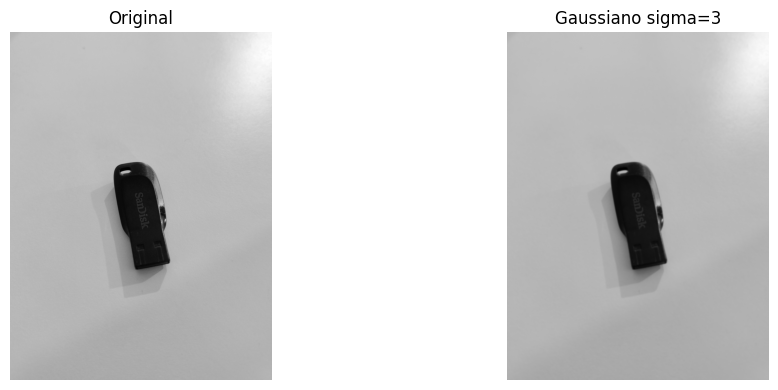

In [17]:
from skimage.filters import gaussian

resGaussian = gaussian(image, sigma=5)

mostra_compara(image, resGaussian, 'Original', 'Gaussiano sigma=3')

* Filtro de Mediana

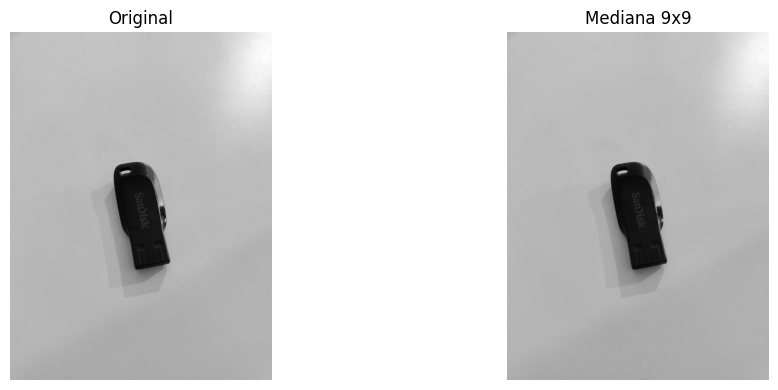

In [18]:
import numpy as np
from skimage.filters import median

# Vamos pegar alguns kernels da aula
K9x9 = np.ones((15, 15), dtype=np.float64)

def medianImage(img, kernel):
    """Filtro da mediana de uma imagem em nivel de cinza."""
    res = median(img, kernel)
    return res

# Aplicação e visualização do filtro de Mediana
resMedian9x9 = medianImage(image, K9x9)

mostra_compara(image, resMedian9x9, 'Original', 'Mediana 9x9')

# Realce de Atributos e Detecção de Bordas

* Prewitt (realce de bordas)

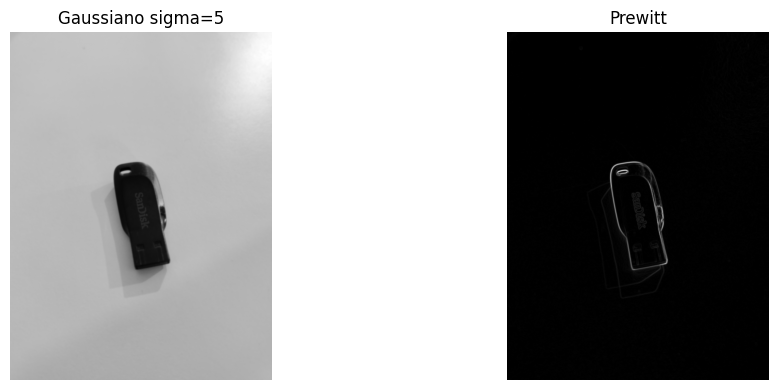

In [19]:
def normalize01(x):
    x = x.astype(np.float64)
    x = x - x.min()
    if x.max() > 0:
        x = x / x.max()
    return x

def grad_magnitude(gx, gy):
    return np.sqrt(gx**2 + gy**2)

gx = prewitt_h(resGaussian)
gy = prewitt_v(resGaussian)
mag = grad_magnitude(gx, gy)

normal_mag = normalize01(mag)

mostra_compara(resGaussian, normal_mag, 'Gaussiano sigma=5', 'Prewitt')

# Segmentação (Limiarização)

* Aplicação de Limiar (Thresholding)

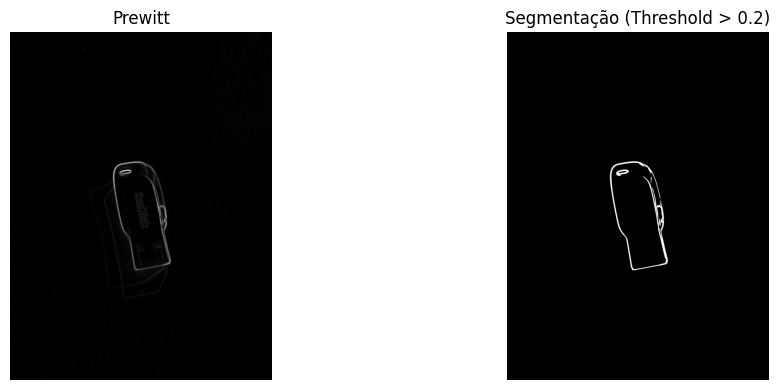

In [20]:
threshold_value = 0.2
binary_segmentation = normal_mag > threshold_value

mostra_compara(normal_mag, binary_segmentation, 'Prewitt', f'Segmentação (Threshold > {threshold_value})')

# Morfologia

* Dilatação a partir de um objeto estruturante

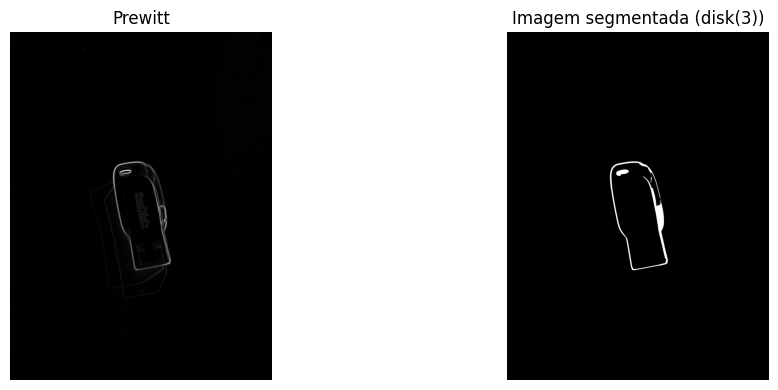

In [21]:
# Usando um elemento estruturante menor para não apagar as bordas finas
struc = disk(3)

# Aplica a morfologia para fechar pequenos buracos no contorno
dilated = binary_dilation(binary_segmentation, struc)
closed = binary_erosion(dilated, struc)

# identifica áreas pretas cercadas por áreas brancas e as preenche
fill_object = ndi.binary_fill_holes(closed)

mostra_compara(normal_mag, fill_object, 'Prewitt', 'Imagem segmentada (disk(3))')

# Detecção de objeto

In [22]:
from skimage.measure import label, regionprops

def recorte_objeto(image):
    # Identifica as manchas brancas
    label_img = label(image)
    regions = regionprops(label_img)

    # Pega o maior objeto
    objeto_principal = max(regions, key=lambda r: r.area)
    minr, minc, maxr, maxc = objeto_principal.bbox

    # Faz o recorte automático
    return image[minr:maxr, minc:maxc]

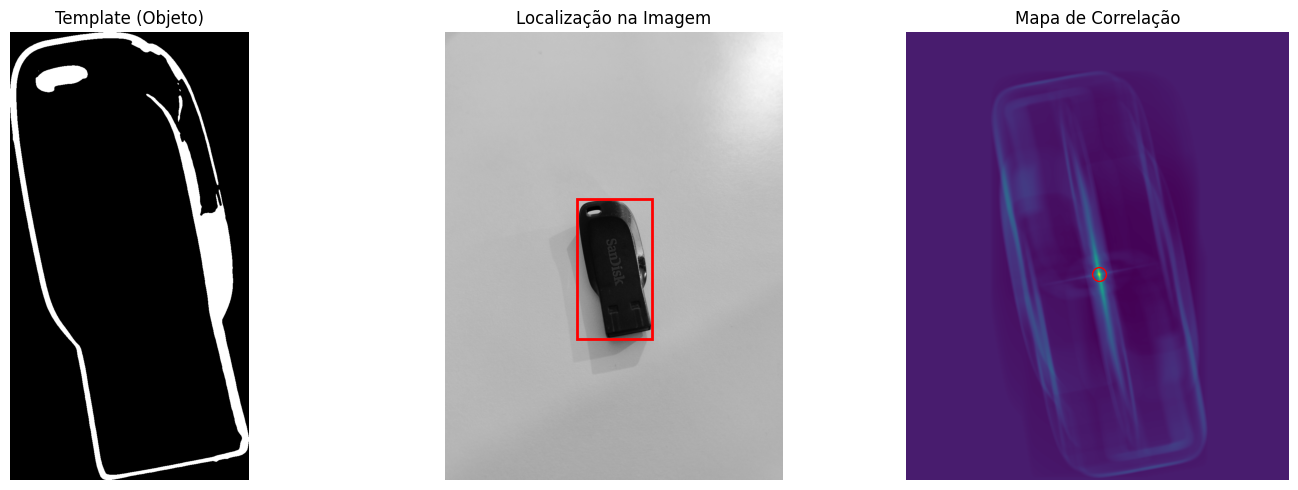

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import match_template

# O template é o recorte do objeto principal
img = recorte_objeto(fill_object)

# Executa a correlação
result = match_template(fill_object, img)
ij = np.unravel_index(np.argmax(result), result.shape)
x, y = ij[::-1]

# Criando a figura
fig = plt.figure(figsize=(15, 5))

# Mostra apenas o Template
ax1 = plt.subplot(1, 3, 1)
ax1.imshow(img, cmap=plt.cm.gray)
ax1.set_title('Template (Objeto)')
ax1.axis('off')

# Mostra a detecção na Imagem Original
ax2 = plt.subplot(1, 3, 2)
ax2.imshow(image, cmap=plt.cm.gray)
ax2.set_title('Localização na Imagem')
himg, wimg = img.shape
rect = plt.Rectangle((x, y), wimg, himg, edgecolor='r', facecolor='none', linewidth=2)
ax2.add_patch(rect)
ax2.axis('off')

# Mostra o mapa de correlação (Heatmap)
ax3 = plt.subplot(1, 3, 3)
ax3.imshow(result)
ax3.set_title('Mapa de Correlação')
ax3.plot(x, y, 'o', markeredgecolor='r', markerfacecolor='none', markersize=10)
ax3.axis('off')

# Ajusta o layout para centralizar e evitar sobreposição
plt.tight_layout()
plt.show()

# Segmentação usando Watershad

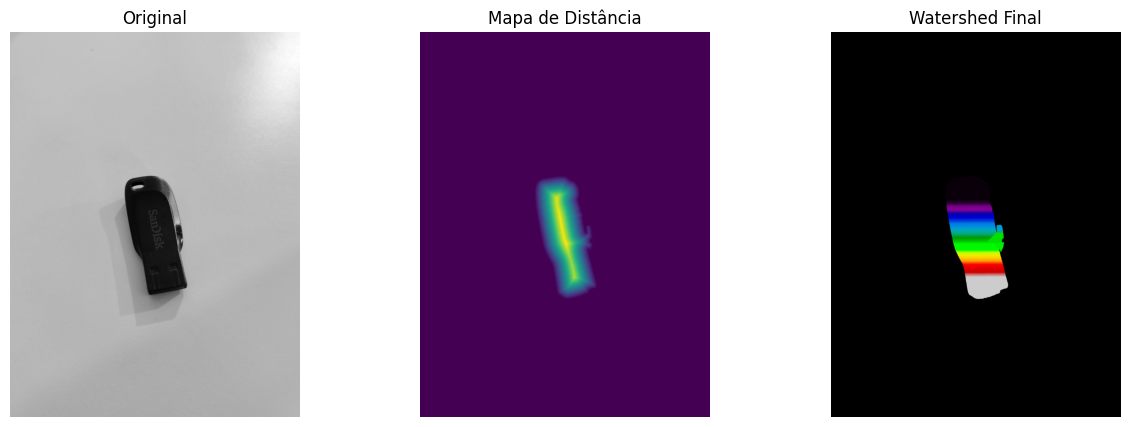

In [24]:
from scipy import ndimage as ndi
from skimage.segmentation import watershed
from skimage.feature import peak_local_max

# Cria uma base binária limpa
thresh = threshold_otsu(resGaussian)
binary = resGaussian < thresh
binary = ndi.binary_fill_holes(binary)

# Mapa de Distância (o centro do objeto vira o ponto mais alto)
distance = ndi.distance_transform_edt(binary)

# Encontra picos (marcadores)
coords = peak_local_max(distance, footprint=np.ones((3, 3)), labels=binary)
mask = np.zeros(distance.shape, dtype=bool)
mask[tuple(coords.T)] = True
markers, _ = ndi.label(mask)

# Watershed (usando a distância invertida para as 'bacias')
labels = watershed(-distance, markers, mask=binary)

# Visualização
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image, cmap='gray'); ax[0].set_title('Original')
ax[1].imshow(distance, cmap='viridis'); ax[1].set_title('Mapa de Distância')
ax[2].imshow(labels, cmap='nipy_spectral'); ax[2].set_title('Watershed Final')
for a in ax: a.axis('off')
plt.show()